In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

assert ".venv" in sys.executable, "Wrong kernel! Switch to 'Python (f1-tyre-strategy)' (top right)."
PROJECT_ROOT = Path.cwd().parent
assert PROJECT_ROOT.name == "f1-tyre-strategy-simulator", "Notebook isn't in the notebooks/ folder!"
sys.path.insert(0, str(PROJECT_ROOT / "src"))   # the saved model needs src/features.py to load

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TARGET = "DeltaToQuali"

model = joblib.load(MODELS_DIR / "lap_time_model.joblib")
meta = json.loads((MODELS_DIR / "lap_time_model_meta.json").read_text())
COLS = meta["input_columns"]
print("Model: ", meta["model"])
print("Inputs:", COLS)

df = pd.read_parquet(PROCESSED_DIR / "laps_clean.parquet")
df = df[df["TyreAge"].notna()].copy()
for col in ["TyreAge", "GreenFlagTyreLaps", "LapNo", "StintNo", "LapsRemaining", "RaceLaps"]:
    df[col] = df[col].astype(float)
trainval = df[df["Split"].isin(["train", "val"])].copy()
test = df[df["Split"] == "test"].copy()

# Model predictions and errors on 2025 (new columns)
test["Pred"] = model.predict(test[COLS])
test["Err"] = test["Pred"] - test[TARGET]
mae = test["Err"].abs().mean()
print(f"\nReloaded model — 2025 test MAE: {mae:.3f} s (saved: {meta['test_2025']['MAE']})")
assert abs(mae - meta["test_2025"]["MAE"]) < 0.001, "Reloaded model doesn't match the saved score!"

# B1 rebuilt from 2022–24, for comparison in every breakdown
b1_tab = trainval.groupby(["Circuit", "Compound"])[TARGET].median().rename("B1")
comp_med = trainval.groupby("Compound")[TARGET].median()
test["PredB1"] = (test.join(b1_tab, on=["Circuit", "Compound"])["B1"]
                  .fillna(test["Compound"].map(comp_med)).fillna(trainval[TARGET].median()))
test["ErrB1"] = test["PredB1"] - test[TARGET]
print(f"B1 test MAE: {test['ErrB1'].abs().mean():.3f} s (saved: {meta['test_2025_B1_MAE']})")
print("✅ Saved model loads and reproduces its test score")

Model:  Ridge v7 (v6 + RaceProgress)
Inputs: ['Compound', 'Circuit', 'TyreAge', 'LapsRemaining', 'TrackTemp', 'AirTemp', 'RaceProgress']

Reloaded model — 2025 test MAE: 1.100 s (saved: 1.1)
B1 test MAE: 1.306 s (saved: 1.306)
✅ Saved model loads and reproduces its test score


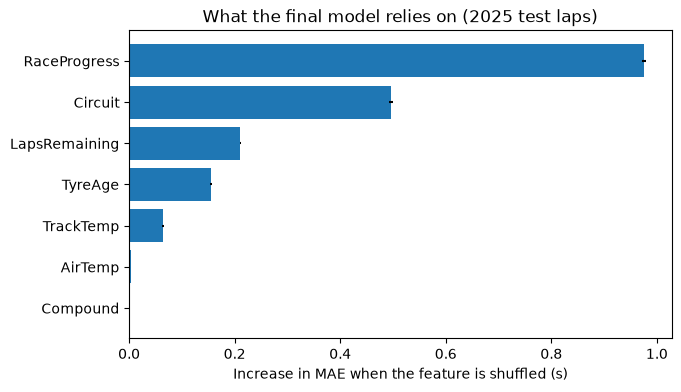

      Feature  Importance    Std
 RaceProgress      0.9750 0.0039
      Circuit      0.4961 0.0042
LapsRemaining      0.2110 0.0013
      TyreAge      0.1550 0.0024
    TrackTemp      0.0642 0.0021
      AirTemp      0.0033 0.0002
     Compound      0.0002 0.0001


In [2]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(model, test[COLS], test[TARGET],
                           scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
imp = pd.DataFrame({"Feature": COLS, "Importance": pi.importances_mean, "Std": pi.importances_std})
imp = imp.sort_values("Importance")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp["Feature"], imp["Importance"], xerr=imp["Std"])
ax.set_xlabel("Increase in MAE when the feature is shuffled (s)")
ax.set_title("What the final model relies on (2025 test laps)")
fig.savefig(FIG_DIR / "04_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.sort_values("Importance", ascending=False).round(4).to_string(index=False))

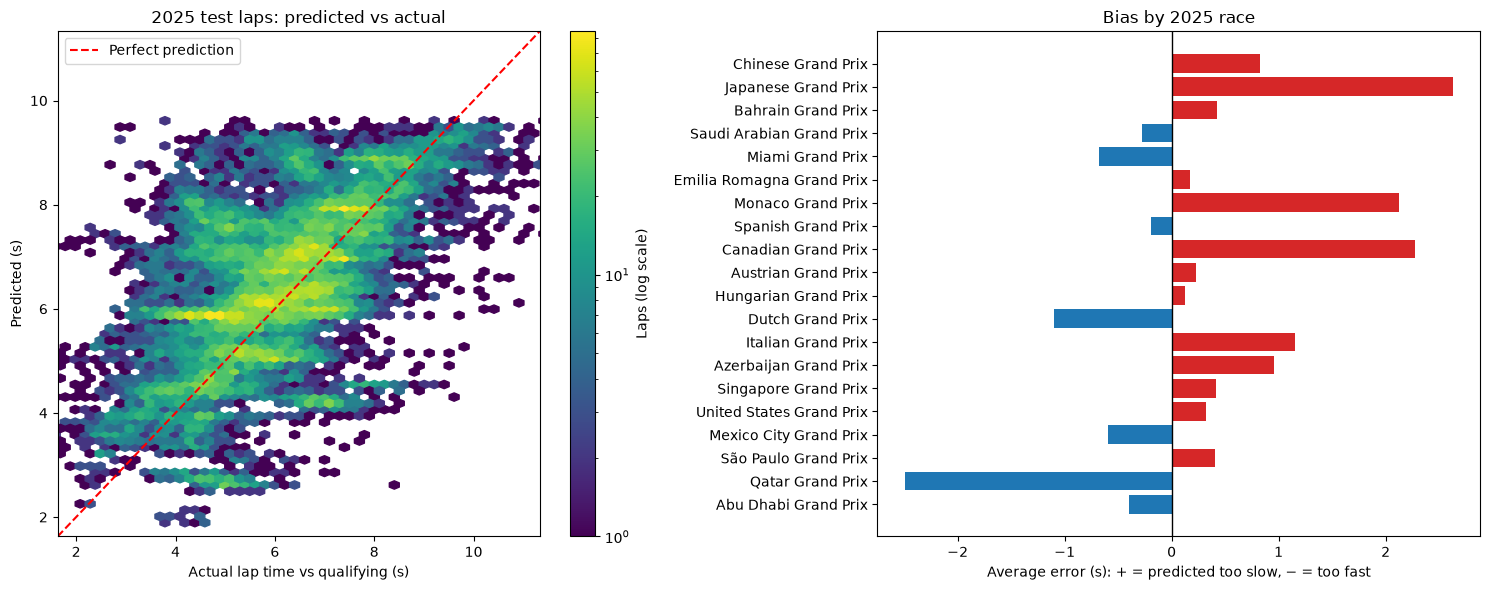

 Round                 EventName   Bias   MAE  Laps
     2        Chinese Grand Prix  0.827 0.952   945
     3       Japanese Grand Prix  2.626 2.632   997
     4        Bahrain Grand Prix  0.427 0.652   932
     5  Saudi Arabian Grand Prix -0.277 0.544   791
     6          Miami Grand Prix -0.681 0.703   511
     7 Emilia Romagna Grand Prix  0.171 0.650   904
     8         Monaco Grand Prix  2.125 2.235  1155
     9        Spanish Grand Prix -0.192 0.553   970
    10       Canadian Grand Prix  2.272 2.278  1161
    11       Austrian Grand Prix  0.228 0.527   978
    14      Hungarian Grand Prix  0.121 0.638  1288
    15          Dutch Grand Prix -1.097 1.103   931
    16        Italian Grand Prix  1.157 1.220   896
    17     Azerbaijan Grand Prix  0.955 1.031   777
    18      Singapore Grand Prix  0.413 0.935  1122
    19  United States Grand Prix  0.325 0.591   906
    20    Mexico City Grand Prix -0.592 0.684  1100
    21      São Paulo Grand Prix  0.408 0.582  1014
    23      

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: every 2025 lap, predicted vs actual (hexagons show where laps pile up)
hb = axes[0].hexbin(test[TARGET], test["Pred"], gridsize=60, mincnt=1, bins="log", cmap="viridis")
lims = [test[TARGET].quantile(0.001), test[TARGET].quantile(0.999)]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("Actual lap time vs qualifying (s)")
axes[0].set_ylabel("Predicted (s)")
axes[0].set_title("2025 test laps: predicted vs actual")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="Laps (log scale)")

# Right: average error (bias) per race — is the season-level shift the same everywhere?
by_race = (test.groupby(["Round", "EventName"])
           .agg(Bias=("Err", "mean"), MAE=("Err", lambda e: e.abs().mean()), Laps=("Err", "size"))
           .reset_index().sort_values("Round", ascending=False))
axes[1].barh(by_race["EventName"], by_race["Bias"],
             color=["tab:red" if b > 0 else "tab:blue" for b in by_race["Bias"]])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Average error (s): + = predicted too slow, − = too fast")
axes[1].set_title("Bias by 2025 race")

fig.tight_layout()
fig.savefig(FIG_DIR / "04_pred_vs_actual_test.png", dpi=150, bbox_inches="tight")
plt.show()
print(by_race.sort_values("Round").round(3).to_string(index=False))

In [4]:
# New grouping columns
test["AgeBand"] = pd.cut(test["TyreAge"], [0, 10, 20, 30, 80], labels=["1–10", "11–20", "21–30", "31+"])
test["ProgressBand"] = pd.cut(test["RaceProgress"], [0, 1/3, 2/3, 1.0],
                              labels=["first third", "middle third", "final third"])


def breakdown(col):
    return (test.groupby(col, observed=True)
            .agg(Laps=("Err", "size"),
                 Model_MAE=("Err", lambda e: e.abs().mean()),
                 Model_Bias=("Err", "mean"),
                 B1_MAE=("ErrB1", lambda e: e.abs().mean()))
            .round(3))


for col in ["Compound", "AgeBand", "ProgressBand", "QualiRefSource"]:
    print(f"\nBy {col}:")
    print(breakdown(col).to_string())

circ = breakdown("Circuit").sort_values("Model_MAE")
print("\nBest 3 circuits:")
print(circ.head(3).to_string())
print("\nWorst 5 circuits:")
print(circ.tail(5).to_string())


By Compound:
          Laps  Model_MAE  Model_Bias  B1_MAE
Compound                                     
HARD      8765      1.245       0.654   1.314
MEDIUM    8028      1.055       0.223   1.286
SOFT      2569      0.749      -0.099   1.341

By AgeBand:
         Laps  Model_MAE  Model_Bias  B1_MAE
AgeBand                                     
1–10     6573      1.054       0.207   1.337
11–20    7132      1.034       0.296   1.275
21–30    3920      1.158       0.513   1.283
31+      1737      1.415       1.026   1.369

By ProgressBand:
              Laps  Model_MAE  Model_Bias  B1_MAE
ProgressBand                                     
first third   6007      1.050       0.285   1.168
middle third  6753      1.120       0.413   1.182
final third   6602      1.126       0.419   1.559

By QualiRefSource:
                 Laps  Model_MAE  Model_Bias  B1_MAE
QualiRefSource                                      
lap_data          666      0.765      -0.401   0.794
results         18553     

In [5]:
race_offset = test.groupby(["Year", "Round"])["Err"].transform("mean")
driver_race_offset = test.groupby(["Year", "Round", "Driver"])["Err"].transform("mean")
within = test["Err"] - driver_race_offset

print(f"Overall lap MAE:                                     {test['Err'].abs().mean():.3f} s")
print(f"After removing each race's average error:            {(test['Err'] - race_offset).abs().mean():.3f} s")
print(f"After removing each driver's average error per race: {within.abs().mean():.3f} s")
share = 1 - (within ** 2).mean() / (test["Err"] ** 2).mean()
print(f"\nShare of squared error that is a fixed offset per driver per race: {share:.0%}")

Overall lap MAE:                                     1.100 s
After removing each race's average error:            0.594 s
After removing each driver's average error per race: 0.503 s

Share of squared error that is a fixed offset per driver per race: 76%


## Notes & findings – 04 Insights

**Saved model check**
- `models/lap_time_model.joblib` (Ridge v7, trained 2022–24) reloads and reproduces the 2025 test MAE of 1.100 s (B1: 1.306 s). The app must add `src/` to the import path, because the model uses `TyreTerms` from `src/features.py`.

**What the model relies on (permutation importance, 2025)**
- RaceProgress 0.975 s · Circuit 0.496 · LapsRemaining 0.211 · TyreAge 0.155 · TrackTemp 0.064 · AirTemp 0.003 · Compound 0.000.
- RaceProgress is inflated: it overlaps with LapsRemaining (collinear), so shuffling one breaks the balance between their large opposite coefficients. Read as: race position + fuel load together matter most.
- Compound ≈ 0 confirms v7 barely uses compound (soft wear under-stated, see 03).

**Predicted vs actual (2025)**
- Predictions are compressed towards the middle (regression towards the mean), with visible race-level bands.
- Bias is race-specific, not one season shift: too slow at Japan +2.63, Canada +2.27, Monaco +2.13, Monza +1.16; too fast at Qatar −2.49, Zandvoort −1.10; about half the races within ±0.45 s.
- One-off rules in training mislead a circuit's level: Qatar 2023 (18-lap tyre limit, flat-out stints) and Monaco 2024 (lap-1 red flag, almost no further stops).

**Where it struggles (MAE, model vs B1)**
- Compound: SOFT 0.749 vs 1.341 · MEDIUM 1.055 vs 1.286 · HARD 1.245 vs 1.314 (bias +0.654).
- Tyre age: 1–10 laps 1.054 · 11–20 1.034 · 21–30 1.158 · 31+ 1.415 vs B1 1.369 (bias +1.026) → straight-line wear over-predicts very long stints (survivor bias).
- Race progress: biggest gain over B1 in the final third (1.126 vs 1.559) – the fuel effect.
- Qualifying reference source: results 1.113 · lap data 0.765 · team-mate 0.805 · teammate_107 1.397 (47 laps).
- Best circuits: Spielberg 0.527, Jeddah 0.544, Yas Island 0.549. Worst: Suzuka 2.632, Lusail 2.493, Montréal 2.278 (unseen), Monaco 2.235, Monza 1.220.

**Error that matters for strategy**
- Lap MAE 1.100 s → 0.594 s after removing each race's average error → **0.503 s** after removing each driver's average error per race.
- **76% of squared error is a fixed offset per driver per race**, which cancels when comparing strategies for the same driver in the same race.

**Implications for the simulator (Stage 5b)**
- Rank strategies within a race rather than predict exact race times.
- Calibrate, using 2022–24 only: soft/medium wear under-predicted; wear on tyres > 30 laps over-predicted.
- App warnings: unseen circuits (Montréal 2025) and races affected by one-off rules.